In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os

print(os.getcwd())
print(os.path.exists("data/IRIS(1).xls"))

/home/finot/Documents/flower
True


In [9]:
import pandas as pd

df = pd.read_csv("data/IRIS(1).xls")

df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


In [10]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [11]:
df["species"].value_counts()

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [12]:
df["species"].value_counts(normalize=True) * 100

species
Iris-setosa        33.333333
Iris-versicolor    33.333333
Iris-virginica     33.333333
Name: proportion, dtype: float64

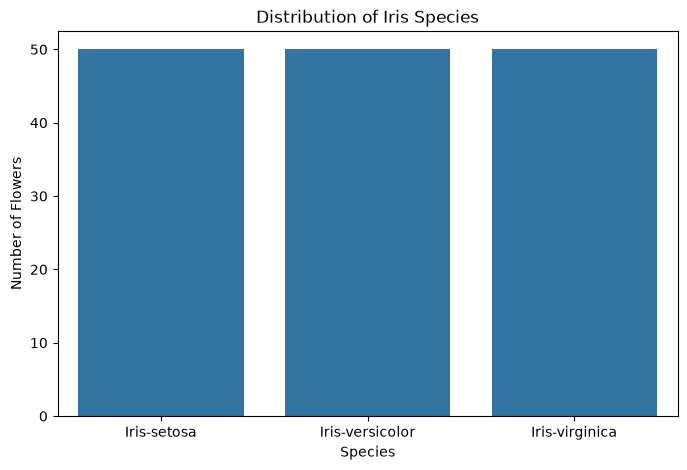

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species"
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")

plt.show()

<Figure size 1200x800 with 0 Axes>

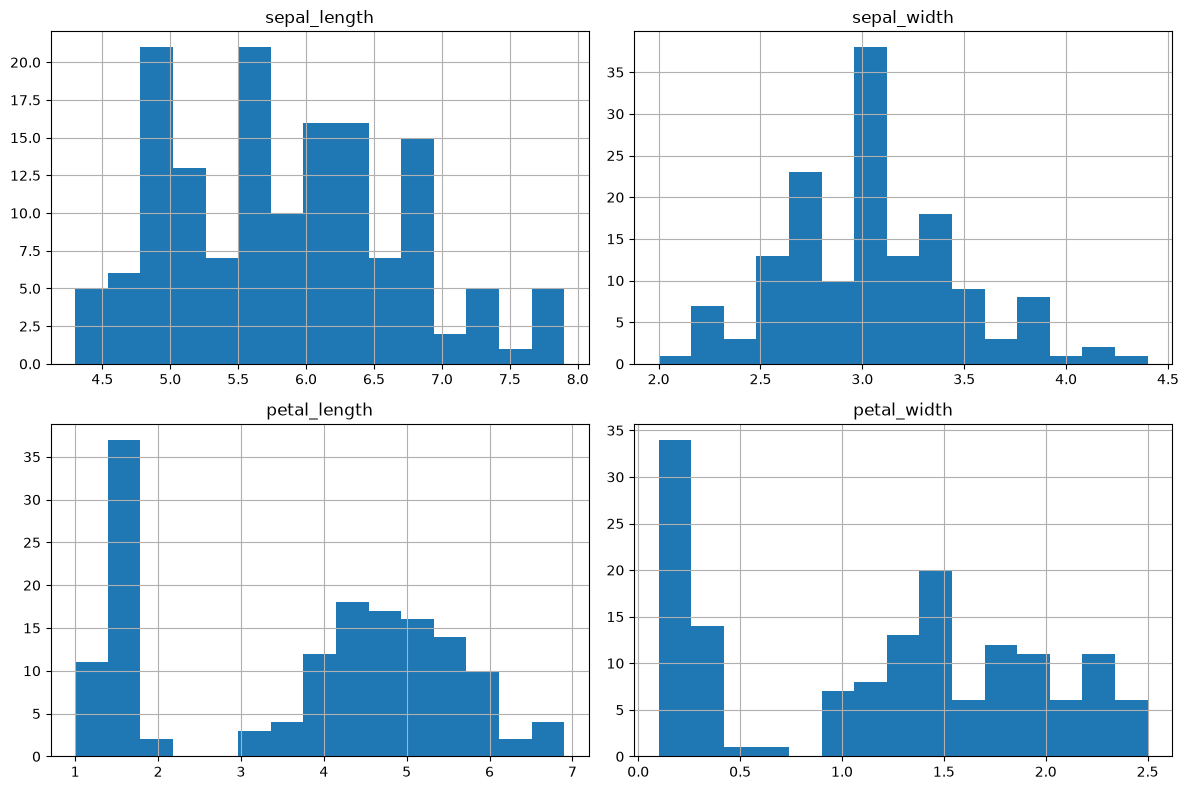

In [14]:
plt.figure(figsize=(12, 8))

df.hist(figsize=(12, 8), bins=15)

plt.tight_layout()
plt.show()

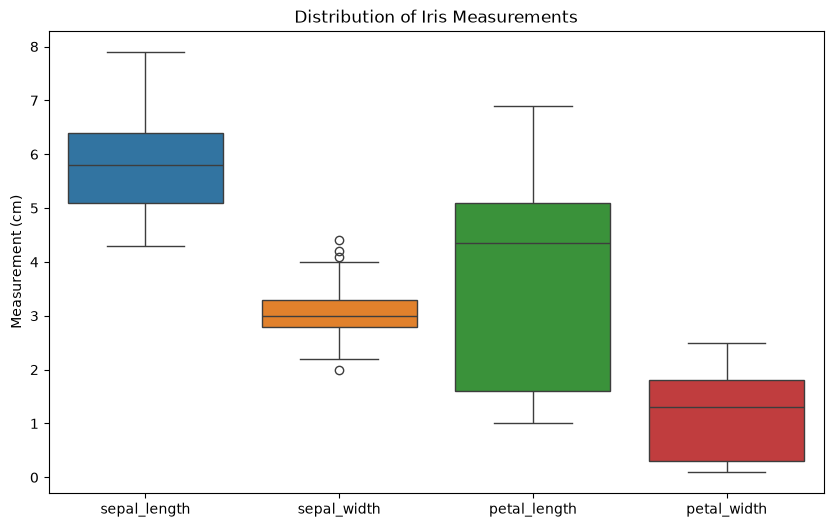

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
])

plt.title("Distribution of Iris Measurements")
plt.ylabel("Measurement (cm)")

plt.show()

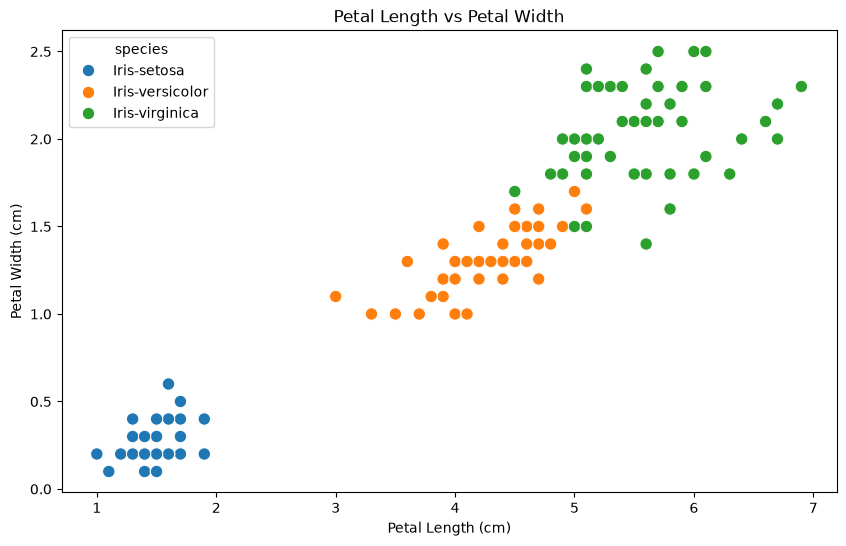

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()

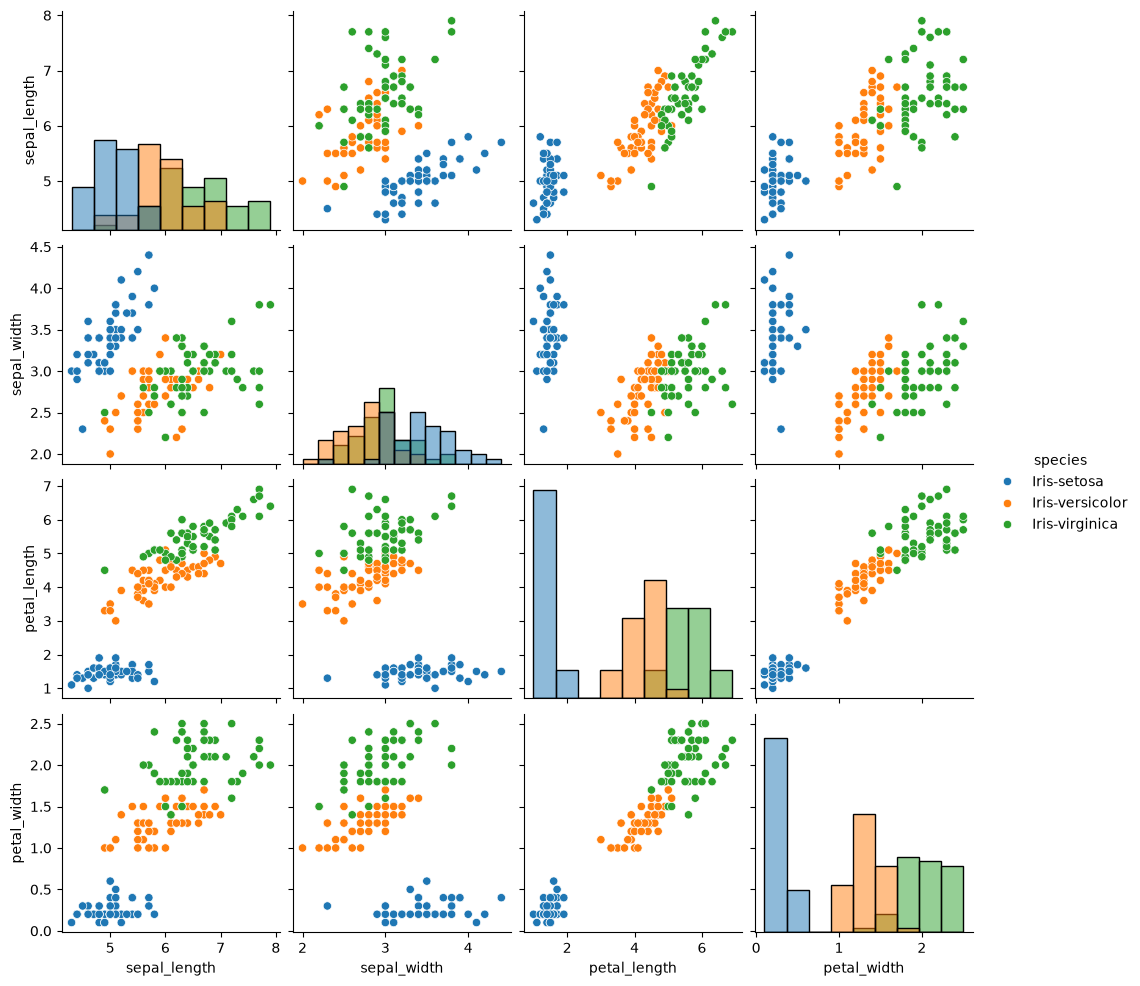

In [17]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

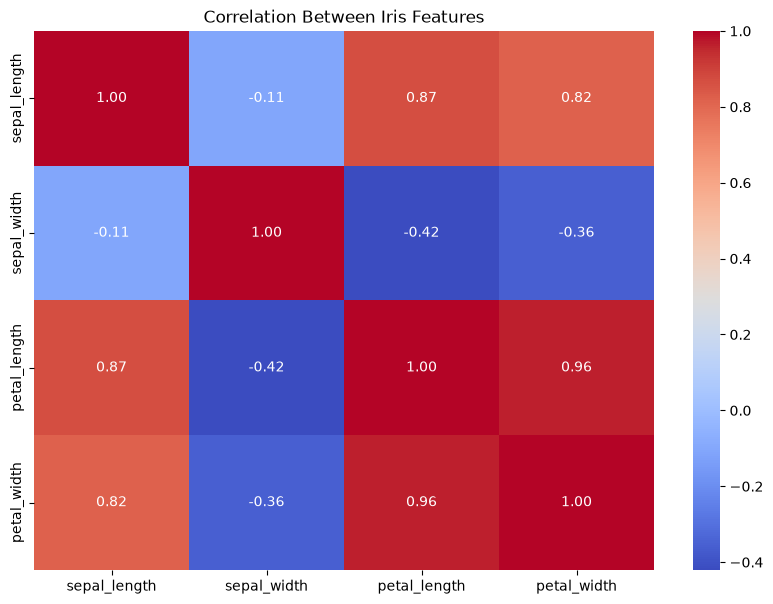

In [18]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Iris Features")

plt.show()

In [20]:
df.duplicated().sum()
df[df.duplicated(keep=False)]

,sepal_length,sepal_width,petal_length,petal_width,species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


In [23]:
X = df.drop("species", axis=1)

y = df["species"]
X = df.drop("species", axis=1)

In [25]:
y = df["species"]
print(X.head())
print(y.head())

   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: species, dtype: str


In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [29]:
from sklearn.preprocessing import StandardScaler

In [33]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)




print("Original training data:")
print(X_train.head())

print("\nScaled training data:")
print(X_train_scaled[:5])

Original training data:
     sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3

Scaled training data:
[[-1.72156775 -0.32483982 -1.34703555 -1.32016847]
 [-1.12449223 -1.22612948  0.41429037  0.65186742]
 [ 1.14439475 -0.55016223  0.58474127  0.25746024]
 [-1.12449223  0.12580502 -1.29021859 -1.45163753]
 [-0.40800161 -1.22612948  0.13020555  0.12599118]]


In [36]:
from sklearn.linear_model import LogisticRegression

# 1. Create the model
log_model = LogisticRegression(max_iter=1000)

# 2. Train the model
log_model.fit(X_train_scaled, y_train)

# 3. Make predictions
y_pred = log_model.predict(X_test_scaled)

print("Model trained successfully!")

Model trained successfully!


In [37]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Accuracy: 0.9333333333333333

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [38]:
import joblib

joblib.dump(log_model, "models/logistic_regression.pkl")
joblib.dump(scaler, "models/scaler.pkl")

['models/scaler.pkl']

In [39]:
import joblib

loaded_model = joblib.load("models/logistic_regression.pkl")
loaded_scaler = joblib.load("models/scaler.pkl")

print(loaded_model)
print(loaded_scaler)

LogisticRegression(max_iter=1000)
StandardScaler()


In [41]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "LDA": LinearDiscriminantAnalysis()
}

In [42]:
from sklearn.metrics import accuracy_score
import pandas as pd
import time

scaled_models = ["Logistic Regression", "KNN", "SVM", "LDA"]

results = []

for name, model in models.items():

    start = time.time()

    if name in scaled_models:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Training Time": time.time() - start
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy", ascending=False
)

results_df

,Model,Accuracy,Training Time
9,LDA,1.000000,0.021169
5,Naive Bayes,0.966667,0.013169
6,Gradient Boosting,0.966667,0.401400
4,SVM,0.966667,0.018330
1,KNN,0.933333,0.074904
0,Logistic Regression,0.933333,0.258417
7,Extra Trees,0.933333,0.216568
2,Decision Tree,0.933333,0.162044
8,AdaBoost,0.933333,0.229223
3,Random Forest,0.900000,0.205748


In [43]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models.items():

    if name in scaled_models:
        pipeline = make_pipeline(StandardScaler(), model)
    else:
        pipeline = model

    scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv, scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean CV Accuracy", ascending=False
)

cv_df

,Model,Mean CV Accuracy,Standard Deviation
9,LDA,0.975000,0.033333
4,SVM,0.966667,0.016667
1,KNN,0.958333,0.026352
0,Logistic Regression,0.958333,0.026352
3,Random Forest,0.950000,0.031180
2,Decision Tree,0.950000,0.016667
5,Naive Bayes,0.950000,0.016667
6,Gradient Boosting,0.950000,0.031180
7,Extra Trees,0.950000,0.031180
8,AdaBoost,0.933333,0.020412


In [44]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

lda_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearDiscriminantAnalysis())
])

lda_params = [
    {
        "model__solver": ["svd"]
    },
    {
        "model__solver": ["lsqr", "eigen"],
        "model__shrinkage": ["auto", 0.1, 0.5, 0.9]
    }
]

lda_grid = GridSearchCV(
    lda_pipeline,
    lda_params,
    cv=5,
    scoring="accuracy"
)

lda_grid.fit(X_train, y_train)

print("Best LDA Parameters:", lda_grid.best_params_)
print("Best LDA CV Accuracy:", lda_grid.best_score_)

Best LDA Parameters: {'model__solver': 'svd'}
Best LDA CV Accuracy: 0.975


In [45]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

svm_params = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring="accuracy"
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:", svm_grid.best_params_)
print("Best SVM CV Accuracy:", svm_grid.best_score_)

Best SVM Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV Accuracy: 0.975


In [46]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

svm_params = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring="accuracy"
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:", svm_grid.best_params_)
print("Best SVM CV Accuracy:", svm_grid.best_score_)

Best SVM Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV Accuracy: 0.975


In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

best_models = {
    "Tuned LDA": lda_grid.best_estimator_,
    "Tuned SVM": svm_grid.best_estimator_
}

print("Both tuned models are ready!")

Both tuned models are ready!


In [49]:
final_model_name = max(
    best_models,
    key=lambda name: accuracy_score(
        y_test,
        best_models[name].predict(X_test)
    )
)

final_model = best_models[final_model_name]

print("Final Model:", final_model_name)

Final Model: Tuned LDA


In [50]:
import joblib

joblib.dump(final_model, "models/final_iris_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

import pandas as pd
import joblib

print("All imports successful!")

All imports successful!


In [4]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

NameError: name 'X_train' is not defined

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the Iris dataset
df = pd.read_csv("data/IRIS(1).xls")

# Separate features (X) and target (y)
X = df.drop("species", axis=1)
y = df["species"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset restored successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Dataset restored successfully!
X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

import joblib
import os

# 1. Define our 10 models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier()
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": make_pipeline(
        StandardScaler(), SVC()
    ),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "LDA": make_pipeline(
        StandardScaler(), LinearDiscriminantAnalysis()
    )
}

# 2. Train and evaluate each model
model_collection = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    model_collection[name] = {
        "model": model,
        "accuracy": accuracy
    }

    print(f"{name}: {accuracy:.2%}")

# 3. Save all models
os.makedirs("models", exist_ok=True)

joblib.dump(
    model_collection,
    "models/iris_models_bundle.pkl"
)

print("\nAll 10 models saved successfully!")

Logistic Regression: 93.33%
KNN: 93.33%
Decision Tree: 93.33%
Random Forest: 90.00%
SVM: 96.67%
Naive Bayes: 96.67%
Gradient Boosting: 96.67%
Extra Trees: 93.33%
AdaBoost: 93.33%
LDA: 100.00%

All 10 models saved successfully!


In [7]:
import os

print(os.path.exists("models/iris_models_bundle.pkl"))

True
